In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

RANDOM_SEED = 2026
FEATURE_COLUMNS = [f"f{i}" for i in range(12)]
SPECIAL_COLUMNS = ["treatment", "exposure", "visit", "conversion"]
EXPECTED_COLUMNS = FEATURE_COLUMNS + SPECIAL_COLUMNS

In [2]:
train_df = pd.read_csv("../data/train.csv.gz")
val_df = pd.read_csv("../data/validation.csv.gz")
test_df = pd.read_csv("../data/test.csv.gz")

print(train_df.shape, val_df.shape, test_df.shape)
assert set(train_df.columns) == set(EXPECTED_COLUMNS), "columns don't match what the notebook expects"

(700000, 16) (150000, 16) (150000, 16)


In [3]:
train_treat = train_df[train_df["treatment"] == 1]
train_ctrl = train_df[train_df["treatment"] == 0]

In [4]:
def evaluate_ranking_by_decile(scores, treatment, visit, n_groups=10):
    d = pd.DataFrame({"score": np.asarray(scores), "treatment": np.asarray(treatment), "visit": np.asarray(visit)})
    d["rank"] = d["score"].rank(method="first", ascending=False)
    d["group"] = pd.qcut(d["rank"], n_groups, labels=False) + 1

    rows = []
    for g, gdf in d.groupby("group"):
        treat, ctrl = gdf[gdf.treatment == 1], gdf[gdf.treatment == 0]
        n_t, n_c = len(treat), len(ctrl)
        p_t, p_c = treat.visit.mean(), ctrl.visit.mean()
        uplift = p_t - p_c
        se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
        z = norm.ppf(0.975)
        rows.append({
            "group": g, "n_treatment": n_t, "n_control": n_c,
            "treatment_visit_rate": p_t, "control_visit_rate": p_c,
            "uplift": uplift, "ci_low": uplift - z * se, "ci_high": uplift + z * se,
        })
    return pd.DataFrame(rows).sort_values("group").reset_index(drop=True)


def incremental_visits(table):
    t = table.copy()
    t["n_group"] = t["n_treatment"] + t["n_control"]
    t["incr_visits"] = t["n_group"] * t["uplift"]
    t["incr_low"] = t["n_group"] * t["ci_low"]
    t["incr_high"] = t["n_group"] * t["ci_high"]
    t["cum_share"] = t["incr_visits"].cumsum() / t["incr_visits"].sum()
    return t[["group", "n_group", "uplift", "incr_visits", "incr_low", "incr_high", "cum_share"]]

In [5]:
for name, g in [("treatment", train_treat), ("control", train_ctrl)]:
    print(f"{name}: {len(g):,} rows, {g['visit'].sum():,} visits, visit rate {g['visit'].mean():.4f}")

treatment: 594,967 rows, 28,791 visits, visit rate 0.0484
control: 105,033 rows, 4,066 visits, visit rate 0.0387


In [6]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def fit_regularized_logreg(df):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    model = make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], cv=cv,
                             scoring="neg_log_loss", max_iter=1000),
    )
    return model.fit(df[FEATURE_COLUMNS], df["visit"])

tl_treat = fit_regularized_logreg(train_treat)
tl_ctrl = fit_regularized_logreg(train_ctrl)

print("chosen C (treatment model):", tl_treat[-1].C_[0])
print("chosen C (control model):  ", tl_ctrl[-1].C_[0])

c:\Users\suman\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\suman\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.w

chosen C (treatment model): 0.1
chosen C (control model):   1.0


In [7]:
scores = {}
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    p_t = tl_treat.predict_proba(df[FEATURE_COLUMNS])[:, 1]
    p_c = tl_ctrl.predict_proba(df[FEATURE_COLUMNS])[:, 1]
    scores[name] = pd.DataFrame({"p_treat": p_t, "p_ctrl": p_c, "uplift": p_t - p_c}, index=df.index)

scores["val"].describe()

,p_treat,p_ctrl,uplift
count,150000.000000,150000.000000,150000.000000
mean,0.047779,0.040752,0.007027
std,0.124271,0.112401,0.022363
min,0.001371,0.001063,-0.097017
25%,0.006093,0.005400,0.000654
50%,0.008162,0.006470,0.001614
75%,0.017184,0.012068,0.003517
max,0.981563,0.976506,0.310151


Treatment model: n=127,493, mean predicted=0.0483, observed=0.0484, Brier=0.03220 (constant-rate baseline 0.04605)
Control model: n=22,507, mean predicted=0.0389, observed=0.0387, Brier=0.02747 (constant-rate baseline 0.03720)


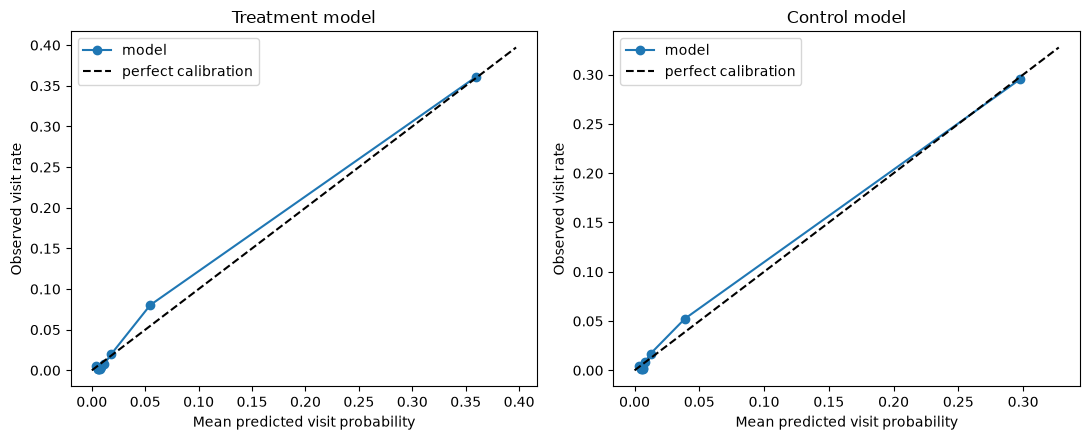

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

val_treat = val_df[val_df["treatment"] == 1]
val_ctrl = val_df[val_df["treatment"] == 0]

checks = [
    ("Treatment model", val_treat, scores["val"].loc[val_treat.index, "p_treat"], train_treat["visit"].mean()),
    ("Control model", val_ctrl, scores["val"].loc[val_ctrl.index, "p_ctrl"], train_ctrl["visit"].mean()),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, group, preds, train_rate) in zip(axes, checks):
    y = group["visit"]
    frac_pos, mean_pred = calibration_curve(y, preds, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label="model")
    lim = max(mean_pred.max(), frac_pos.max()) * 1.1
    ax.plot([0, lim], [0, lim], "k--", label="perfect calibration")
    ax.set_xlabel("Mean predicted visit probability")
    ax.set_ylabel("Observed visit rate")
    ax.set_title(name)
    ax.legend()

    brier = brier_score_loss(y, preds)
    brier_const = brier_score_loss(y, np.full(len(y), train_rate))
    print(f"{name}: n={len(y):,}, mean predicted={preds.mean():.4f}, observed={y.mean():.4f}, "
          f"Brier={brier:.5f} (constant-rate baseline {brier_const:.5f})")
plt.tight_layout()
plt.show()

In [9]:
t_learner_task_table = evaluate_ranking_by_decile(
    scores["val"]["uplift"], val_df["treatment"], val_df["visit"]
)
display(t_learner_task_table)
display(incremental_visits(t_learner_task_table))

,group,n_treatment,n_control,treatment_visit_rate,control_visit_rate,uplift,ci_low,ci_high
0,1,12975,2025,0.258497,0.197531,0.060966,0.042060,0.079873
1,2,12765,2235,0.059381,0.047427,0.011954,0.002235,0.021673
2,3,12741,2259,0.024802,0.027888,-0.003087,-0.010394,0.004221
3,4,12679,2321,0.013960,0.013787,0.000173,-0.004992,0.005338
4,5,12671,2329,0.007655,0.010734,-0.003079,-0.007531,0.001373
5,6,12726,2274,0.005265,0.006157,-0.000892,-0.004344,0.002560
6,7,12657,2343,0.005294,0.004695,0.000599,-0.002444,0.003642
7,8,12780,2220,0.003521,0.003604,-0.000082,-0.002778,0.002613
8,9,12758,2242,0.002195,0.002230,-0.000035,-0.002150,0.002079
9,10,12741,2259,0.098972,0.091633,0.007338,-0.005640,0.020317


,group,n_group,uplift,incr_visits,incr_low,incr_high,cum_share
0,1,15000,0.060966,914.493684,630.898621,1198.088748,0.825488
1,2,15000,0.011954,179.307408,33.522004,325.092811,0.987344
2,3,15000,-0.003087,-46.299380,-155.906630,63.307871,0.945551
3,4,15000,0.000173,2.593962,-74.877675,80.065598,0.947892
4,5,15000,-0.003079,-46.184173,-112.960427,20.592081,0.906203
5,6,15000,-0.000892,-13.376102,-65.157773,38.405569,0.894129
6,7,15000,0.000599,8.980167,-36.663647,54.623981,0.902235
7,8,15000,-0.000082,-1.237153,-41.675505,39.201200,0.901118
8,9,15000,-0.000035,-0.531754,-32.252462,31.188953,0.900638
9,10,15000,0.007338,110.075357,-84.596809,304.747522,1.000000
